# Home Credit — Credit Risk, Probability of Default & Expected Loss

A complete, reproducible **retail credit-risk case study** using the public Home Credit Default Risk dataset (25-column teaching extract or full application_train.csv). This notebook is self-contained and requires **no personal data** in the repository.

**Key research questions:** Which applicant characteristics best separate repayment difficulties? How does model re-calibration affect expected loss estimates?

**Process:** EDA → 60/20/20 stratified split → train-only supervised WoE & IV → weighted logistic regression → independent sigmoid PD calibration → ROC/PR, Brier, reliability → illustrative expected loss.

> TARGET=1 corresponds to **payment difficulties**, a benchmark event label, rather than a directly validated regulatory default definition. LGD=45% and EAD=loan amount are educational assumptions, not empirical estimates.

**Dataset:** [Home Credit Default Risk on Kaggle](https://www.kaggle.com/c/home-credit-default-risk/data). Download `application_train.csv`. Alternatively, use your provided file `application (1).csv` (25-column extract). The dataset is **not included** in this repository.


In [ ]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<4" "scikit-learn>=1.6,<2" "matplotlib>=3.8,<4"

## 1 · Setup and input checks

All features are known at application time; we deliberately use six selected quantitative variables to preserve interpretability.

In [2]:
"""Home Credit credit-risk analysis: train-only WoE, calibrated logistic PD, illustrative EL.

Run with: python credit_risk.py --data '/path/to/application_train.csv'
No customer-level data is written to the public repository by default.
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             confusion_matrix, log_loss, roc_auc_score, roc_curve,
                             precision_recall_curve)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

FEATURES = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
            "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
TARGET = "TARGET"
ID = "SK_ID_CURR"
RANDOM_STATE = 42
LGD_ASSUMED = 0.45




In [3]:
def load_data(path: str | Path) -> pd.DataFrame:
    """Read the Home Credit 25-column teaching extract or Kaggle application_train.csv."""
    frame = pd.read_csv(path, low_memory=False)
    required = [ID, TARGET, *FEATURES]
    missing = [col for col in required if col not in frame.columns]
    if missing:
        raise ValueError(f"Missing required Home Credit columns: {missing}")
    if frame[ID].isna().any() or frame[ID].duplicated().any():
        raise ValueError("Customer IDs must be unique and non-missing.")
    frame = frame[required].copy()
    for col in [TARGET, *FEATURES]:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    if frame[TARGET].isna().any() or not frame[TARGET].isin([0, 1]).all():
        raise ValueError("TARGET must contain only 0 (non-default) and 1 (default).")
    if frame["AMT_CREDIT"].isna().any() or (frame["AMT_CREDIT"] <= 0).any():
        raise ValueError("AMT_CREDIT must be strictly positive for an EAD proxy.")
    frame[TARGET] = frame[TARGET].astype(int)
    return frame


## 2 · Separate model development, calibration and test

The stratified 60%/20%/20% split is fixed by `random_state=42`. No supervised preparation step sees calibration or test labels.

In [4]:
def split_data(df: pd.DataFrame):
    """60% model development, 20% calibration, 20% final test (stratified)."""
    dev, test = train_test_split(df, test_size=0.2, stratify=df[TARGET],
                                 random_state=RANDOM_STATE)
    train, calibration = train_test_split(dev, test_size=0.25,
                                          stratify=dev[TARGET], random_state=RANDOM_STATE)
    return train, calibration, test


## 3 · Weight of Evidence and Information Value

Supervised tree cuts are learned **on the training sample only**, then applied unchanged to the other subsets. Missing values use a dedicated bin when present in training. WoE is defined as `ln(share of non-defaults / share of defaults)`, with additive smoothing; IV adds `(good_share−bad_share) × WoE` across bins.

This implementation uses scikit-learn instead of `scorecardpy`; both estimate WoE, but their cutpoints and results are **not identical**.

In [5]:
class TrainOnlyWoE:
    """Supervised decision-tree bins and smoothed Weight of Evidence.

    Each feature's cut points are learned from train only. Missing observations
    receive an explicit bin. WoE = log(share_of_goods / share_of_bads).
    Tree cutpoints do not rely on scorecardpy so the project runs offline.
    """

    def __init__(self, max_bins: int = 5, min_leaf_fraction: float = 0.05, smoothing: float = 0.5):
        self.max_bins = max_bins
        self.min_leaf_fraction = min_leaf_fraction
        self.smoothing = smoothing
        self.thresholds_: dict[str, np.ndarray] = {}
        self.woe_maps_: dict[str, dict[str, float]] = {}
        self.tables_: dict[str, pd.DataFrame] = {}
        self.iv_: dict[str, float] = {}

    def _assign_bins(self, s: pd.Series, feature: str) -> pd.Series:
        raw = pd.to_numeric(s, errors="coerce")
        thresholds = self.thresholds_[feature]
        result = pd.Series(index=raw.index, dtype="object")
        good = raw.notna()
        result.loc[good] = [f"bin_{i}" for i in np.searchsorted(
            thresholds, raw.loc[good].to_numpy(), side="left")]
        result.loc[~good] = "missing"
        return result

    def fit(self, x: pd.DataFrame, y: pd.Series) -> "TrainOnlyWoE":
        if x.empty or len(x) != len(y):
            raise ValueError("Feature matrix must be non-empty and align with the target.")
        if not x.index.equals(y.index):
            raise ValueError("X/y indices must match in WoE training.")
        y = y.astype(int)
        if set(y.unique()) != {0, 1}:
            raise ValueError("WoE requires both target classes (0/1).")
        self.thresholds_.clear()
        self.woe_maps_.clear()
        self.tables_.clear()
        self.iv_.clear()
        for feature in x.columns:
            series = pd.to_numeric(x[feature], errors="coerce")
            observed = series.notna()
            if observed.sum() >= 20 and series.loc[observed].nunique() > 1:
                tree = DecisionTreeClassifier(
                    max_leaf_nodes=self.max_bins, min_samples_leaf=self.min_leaf_fraction,
                    random_state=RANDOM_STATE)
                tree.fit(series.loc[observed].to_numpy().reshape(-1, 1), y.loc[observed])
                thresholds = np.sort(tree.tree_.threshold[tree.tree_.feature >= 0])
            else:
                thresholds = np.array([], dtype=float)
            self.thresholds_[feature] = np.asarray(thresholds, dtype=float)
            bins = self._assign_bins(series, feature)
            tbl = pd.DataFrame({"bin": bins, "target": y})
            counts = (tbl.groupby("bin", sort=True)["target"]
                      .agg(count="size", defaults="sum"))
            counts["non_defaults"] = counts["count"] - counts["defaults"]
            k = len(counts)
            pct_good = (counts["non_defaults"] + self.smoothing) / (
                counts["non_defaults"].sum() + self.smoothing * k)
            pct_bad = (counts["defaults"] + self.smoothing) / (
                counts["defaults"].sum() + self.smoothing * k)
            counts["woe"] = np.log(pct_good / pct_bad)
            counts["bin_iv"] = (pct_good - pct_bad) * counts["woe"]
            counts["default_rate"] = counts["defaults"] / counts["count"]
            counts = counts.reset_index()
            # Explicitly retain the ordered interval boundaries for auditability.
            def interval_label(label: str) -> str:
                if label == "missing":
                    return "Missing"
                j = int(label.split("_")[1])
                left = "-inf" if j == 0 else f"{thresholds[j - 1]:.6g}"
                right = "+inf" if j == len(thresholds) else f"{thresholds[j]:.6g}"
                return f"({left}, {right}]"
            counts["interval"] = counts["bin"].map(interval_label)
            self.tables_[feature] = counts[["bin", "interval", "count", "defaults",
                                            "default_rate", "woe", "bin_iv"]]
            self.woe_maps_[feature] = counts.set_index("bin")["woe"].to_dict()
            self.iv_[feature] = float(counts["bin_iv"].sum())
        return self

    def transform(self, x: pd.DataFrame) -> pd.DataFrame:
        if not self.woe_maps_:
            raise RuntimeError("Fit the WoE encoder on the training sample first.")
        out = pd.DataFrame(index=x.index)
        for feature in self.woe_maps_:
            bins = self._assign_bins(x[feature], feature)
            # A missing bin unseen during training is mapped to neutral WoE=0.
            # Observed numerical bins always have support because of ±infinity edges.
            out[f"{feature}_woe"] = bins.map(self.woe_maps_[feature]).fillna(0.0).astype(float)
            if not np.isfinite(out[f"{feature}_woe"]).all():
                raise ValueError(f"Missing or infinite WoE for feature {feature}")
        return out


## 4 · Weighted logistic PD model and calibration

A class-balanced logistic model improves the penalty attached to the minority class but typically shifts the raw average predicted PD well above the portfolio default rate. We calibrate the *already fitted* model on a **distinct 20% calibration sample**, using sigmoid/Platt scaling. The test set is used only for final evaluation.

In [6]:
def fit_models(train: pd.DataFrame, calibration: pd.DataFrame):
    """Keep all supervised transformations in training; Platt calibration on holdout."""
    encoder = TrainOnlyWoE().fit(train[FEATURES], train[TARGET])
    x_train = encoder.transform(train[FEATURES])
    x_cal = encoder.transform(calibration[FEATURES])
    model = LogisticRegression(class_weight="balanced", max_iter=1000,
                               random_state=RANDOM_STATE)
    model.fit(x_train, train[TARGET])
    calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
    calibrated.fit(x_cal, calibration[TARGET])
    return encoder, model, calibrated


## 5 · Model evaluation and educational Expected Loss

ROC-AUC and average precision assess discriminatory power, while Brier and log loss assess probability quality. The confusion matrix is explicitly based on the **raw balanced classifier at threshold 0.5**, not on an optimized loan-approval cutoff.

Expected loss proxy: `EL_i = calibrated_PD_i × 0.45 × AMT_CREDIT_i`. There is no observed loss or contractual EAD at default in this model.

In [7]:
def calculate_metrics(test: pd.DataFrame, pd_raw: np.ndarray,
                      pd_cal: np.ndarray, labels_balanced: np.ndarray,
                      train_default_rate: float) -> dict:
    y = test[TARGET].to_numpy()
    if (len(y) != len(pd_raw)) or (len(y) != len(pd_cal)):
        raise ValueError("PD and target lengths do not match")
    if ((np.asarray(pd_cal) < 0) | (np.asarray(pd_cal) > 1)).any():
        raise ValueError("Calibrated PD must fall in [0,1].")
    ead = test["AMT_CREDIT"].to_numpy(dtype=float)  # proxy, not actual future EAD
    el = pd_cal * LGD_ASSUMED * ead
    cm = confusion_matrix(y, labels_balanced)
    return {
        "n_test": int(len(y)),
        "default_rate": float(y.mean()),
        "mean_pd_raw": float(pd_raw.mean()),
        "mean_pd_calibrated": float(pd_cal.mean()),
        "auc_raw": float(roc_auc_score(y, pd_raw)),
        "auc_calibrated": float(roc_auc_score(y, pd_cal)),
        "average_precision_raw": float(average_precision_score(y, pd_raw)),
        "average_precision_calibrated": float(average_precision_score(y, pd_cal)),
        "brier_raw": float(brier_score_loss(y, pd_raw)),
        "brier_calibrated": float(brier_score_loss(y, pd_cal)),
        "brier_constant_baseline": float(brier_score_loss(y, np.full(len(y), train_default_rate))),
        "log_loss_raw": float(log_loss(y, pd_raw)),
        "log_loss_calibrated": float(log_loss(y, pd_cal)),
        "balanced_threshold_confusion_matrix": cm.tolist(),
        "balanced_threshold_classification_report": classification_report(
            y, labels_balanced, output_dict=True, zero_division=0),
        "ead_proxy_total": float(ead.sum()),
        "lgd_assumed": float(LGD_ASSUMED),
        "expected_loss_proxy_total": float(el.sum()),
        "expected_loss_to_ead": float(el.sum() / ead.sum()),
    }


## 6 · Visualization, aggregated reports and full workflow

In [8]:
def save_plots(y: np.ndarray, raw: np.ndarray, cal: np.ndarray, iv: pd.Series,
               out_dir: Path):
    out_dir.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    iv.sort_values().plot(kind="barh", ax=ax, color="#2362a1")
    ax.set_xlabel("Information Value (train only)")
    ax.set_title("Predictive strength of selected features")
    fig.tight_layout(); fig.savefig(out_dir / "01_information_value.png", dpi=170); plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 5))
    for prob, name in ((raw, "Weighted logistic"), (cal, "Calibrated PD")):
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, label=f"{name}: AUC {roc_auc_score(y,prob):.3f}")
    ax.plot([0,1], [0,1], linestyle="--", color="gray", label="Random")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("Out-of-sample ROC curves"); ax.legend()
    fig.tight_layout(); fig.savefig(out_dir / "02_roc_curve.png", dpi=170); plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 5))
    for prob, name in ((raw, "Before calibration"), (cal, "After calibration")):
        actual, predicted = calibration_curve(y, prob, n_bins=10, strategy="quantile")
        ax.plot(predicted, actual, marker="o", label=name)
    ax.plot([0,1], [0,1], linestyle="--", color="gray", label="Perfect calibration")
    ax.set_xlabel("Mean predicted PD"); ax.set_ylabel("Observed default frequency")
    ax.set_title("Reliability diagram – test sample"); ax.legend()
    fig.tight_layout(); fig.savefig(out_dir / "03_calibration.png", dpi=170); plt.close(fig)

    fig, ax = plt.subplots(figsize=(7.6, 5))
    p, recall, _ = precision_recall_curve(y, cal)
    ax.plot(recall, p, label=f"Calibrated model: AP {average_precision_score(y,cal):.3f}")
    ax.axhline(float(y.mean()), color="gray", linestyle="--", label="Default prevalence")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title("Precision–recall: minority default class"); ax.legend()
    fig.tight_layout(); fig.savefig(out_dir / "04_precision_recall.png", dpi=170); plt.close(fig)


In [9]:
def run_analysis(data_path: str | Path, output_dir: str | Path = "results") -> dict:
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    df = load_data(data_path)
    train, cal, test = split_data(df)
    encoder, raw_model, model_cal = fit_models(train, cal)
    x_test = encoder.transform(test[FEATURES])
    pd_raw = raw_model.predict_proba(x_test)[:, 1]
    pd_cal = model_cal.predict_proba(x_test)[:, 1]
    predicted_balanced = raw_model.predict(x_test)
    metrics = calculate_metrics(test, pd_raw, pd_cal, predicted_balanced, train[TARGET].mean())
    metrics.update({
        "n_total": int(len(df)), "n_train": int(len(train)), "n_calibration": int(len(cal)),
        "overall_default_rate": float(df[TARGET].mean()),
        "sample_missing_rates": {feat: float(df[feat].isna().mean()) for feat in FEATURES},
        "method": "Decision-tree supervised WoE bins trained on train only; weighted logistic; held-out sigmoid calibration",
        "split_random_seed": RANDOM_STATE,
    })
    pd.Series(encoder.iv_, name="IV").sort_values(ascending=False).to_csv(out / "information_value.csv", header=True)
    all_bins = pd.concat([table.assign(feature=feature) for feature, table in encoder.tables_.items()],
                         ignore_index=True)
    all_bins.to_csv(out / "woe_binning_table.csv", index=False)
    pd.DataFrame({"Feature": FEATURES, "Logistic coefficient": raw_model.coef_[0]}) \
        .to_csv(out / "logistic_coefficients.csv", index=False)
    # Save anonymized aggregate decile table only; no customer data or PD rows.
    deciles = pd.qcut(pd.Series(pd_cal), q=10, labels=False, duplicates="drop")
    decile_frame = pd.DataFrame({"decile": deciles, "pd": pd_cal, "default": test[TARGET].to_numpy(),
                                 "exposure": test["AMT_CREDIT"].to_numpy(),
                                 "EL": pd_cal * LGD_ASSUMED * test["AMT_CREDIT"].to_numpy()})
    decile_summary = decile_frame.groupby("decile").agg(
        clients=("pd", "size"), mean_predicted_pd=("pd", "mean"),
        observed_default_rate=("default", "mean"),
        exposure_proxy=("exposure", "sum"), expected_loss_proxy=("EL", "sum"))
    decile_summary.to_csv(out / "pd_deciles.csv")
    save_plots(test[TARGET].to_numpy(), pd_raw, pd_cal,
               pd.Series(encoder.iv_, name="IV"), out / "figures")
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print("DATA:", len(df), "clients; train/cal/test:", len(train), len(cal), len(test))
    print("DEFAULT RATE: {:.2%}".format(df[TARGET].mean()))
    print("IV:\n", pd.Series(encoder.iv_).sort_values(ascending=False))
    print("CONFUSION MATRIX (weighted model, threshold = 0.5):\n",
          confusion_matrix(test[TARGET], predicted_balanced))
    for key in ("auc_calibrated", "average_precision_calibrated", "brier_raw",
                "brier_calibrated", "brier_constant_baseline", "default_rate",
                "mean_pd_raw", "mean_pd_calibrated", "expected_loss_proxy_total",
                "ead_proxy_total", "expected_loss_to_ead"):
        print(f"{key}: {metrics[key]:,.6f}")
    print("Saved aggregate outputs:", out.resolve())
    return metrics


## 7 · Run on your dataset

Upload your Home Credit CSV if prompted. The notebook writes **only aggregate** outputs to the local `results/` folder; it does not export customer-level predictions.

In [10]:
from pathlib import Path
candidates = [Path("application (1).csv"), Path("application_train.csv"), Path("APPLICATION.CSV")]
found = next((p for p in candidates if p.is_file()), None)
if found is None:
    try:
        from google.colab import files
        print("Upload application_train.csv (or your application (1).csv extract)")
        uploaded = files.upload()
        found = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("Place the Home Credit CSV in the notebook directory, or run on Google Colab.")
print("Reading:", found.name)
metrics = run_analysis(found, Path("results"))


Reading: application (1).csv


DATA: 307511 clients; train/cal/test: 184506 61502 61503
DEFAULT RATE: 8.07%
IV:
 EXT_SOURCE_3        0.322721
EXT_SOURCE_2        0.292373
EXT_SOURCE_1        0.147626
AMT_CREDIT          0.056372
AMT_ANNUITY         0.028546
AMT_INCOME_TOTAL    0.013213
dtype: float64
CONFUSION MATRIX (weighted model, threshold = 0.5):
 [[38234 18304]
 [ 1702  3263]]
auc_calibrated: 0.725571
average_precision_calibrated: 0.206311
brier_raw: 0.210331
brier_calibrated: 0.069589
brier_constant_baseline: 0.074211
default_rate: 0.080728
mean_pd_raw: 0.436760
mean_pd_calibrated: 0.080114
expected_loss_proxy_total: 1,200,182,055.251873
ead_proxy_total: 36,765,080,145.000000
expected_loss_to_ead: 0.032645
Saved aggregate outputs: /mnt/data/results


Detailed training-only IV rankings:


,Unnamed: 0,IV
0,EXT_SOURCE_3,0.322721
1,EXT_SOURCE_2,0.292373
2,EXT_SOURCE_1,0.147626
3,AMT_CREDIT,0.056372
4,AMT_ANNUITY,0.028546
5,AMT_INCOME_TOTAL,0.013213


Test calibration deciles (aggregated):


,decile,clients,mean_predicted_pd,observed_default_rate,exposure_proxy,expected_loss_proxy
0,0,6173,0.019451,0.019763,5.293062e+09,4.488984e+07
1,1,6132,0.028997,0.026745,4.075713e+09,5.327094e+07
2,2,6147,0.036398,0.035464,3.849313e+09,6.302043e+07
3,3,6153,0.046357,0.042581,3.766816e+09,7.830219e+07
4,4,6163,0.054788,0.047542,3.643667e+09,8.979808e+07
5,5,6135,0.065738,0.066015,3.392296e+09,1.005017e+08
6,6,6233,0.081527,0.082946,3.470705e+09,1.273856e+08
7,7,6108,0.102013,0.105763,3.224904e+09,1.482570e+08
8,8,6110,0.134384,0.135516,3.083971e+09,1.866082e+08
9,9,6149,0.232089,0.245568,2.964633e+09,3.081481e+08


01_information_value.png


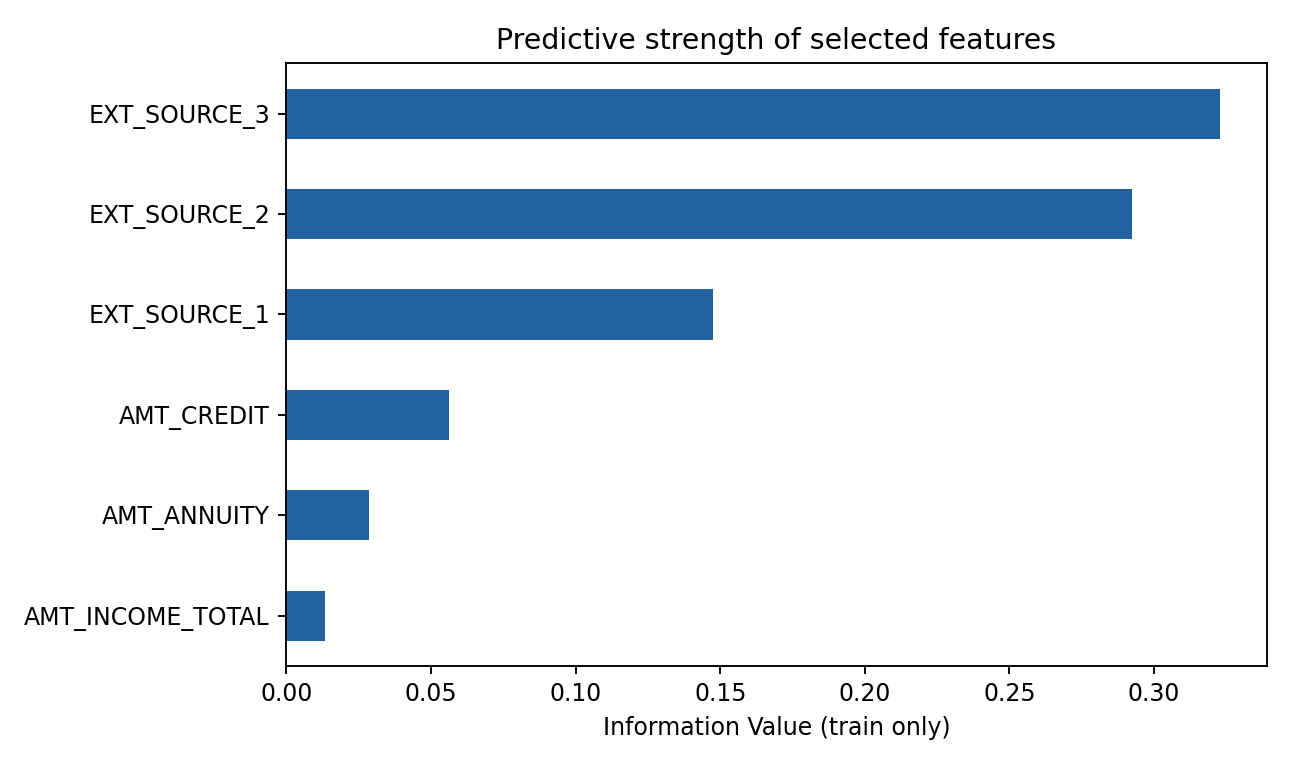

02_roc_curve.png


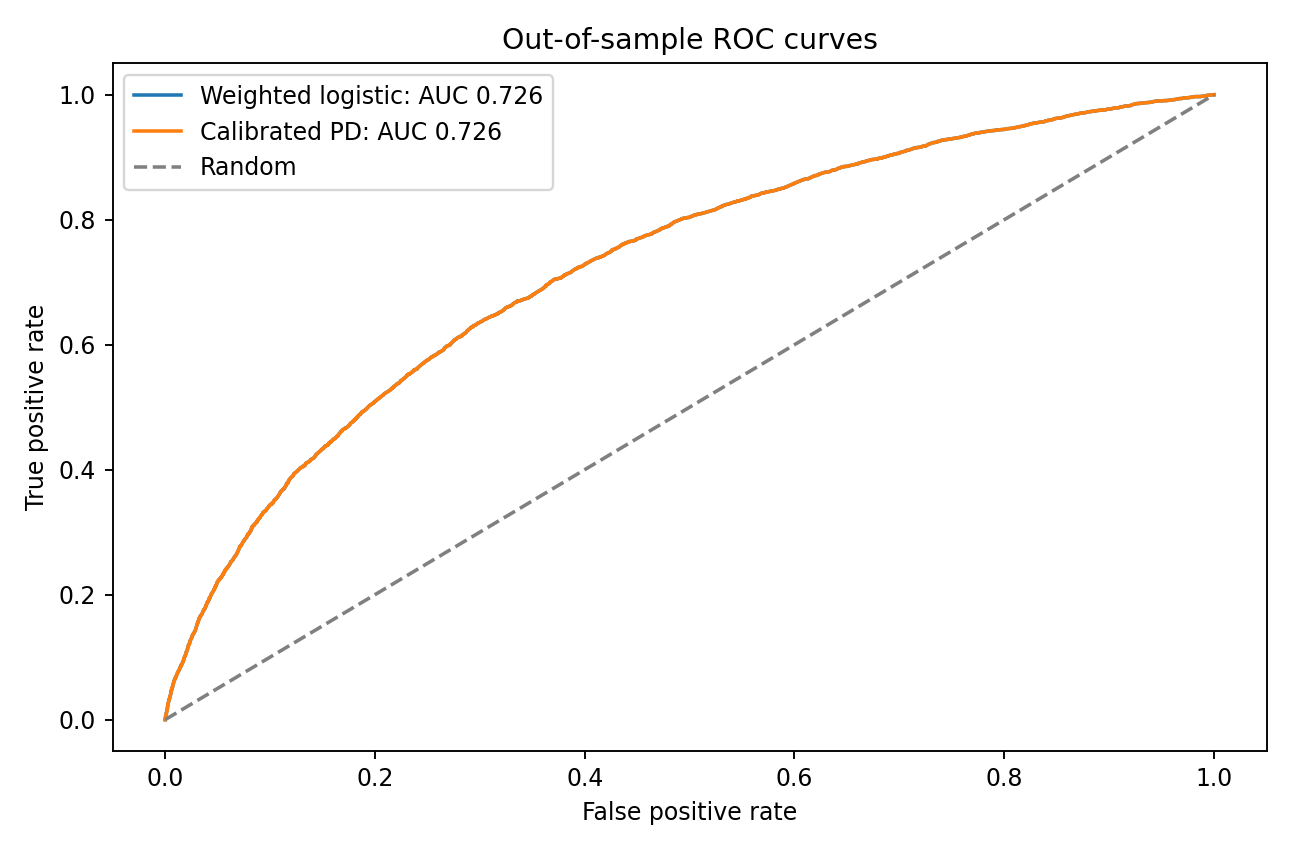

03_calibration.png


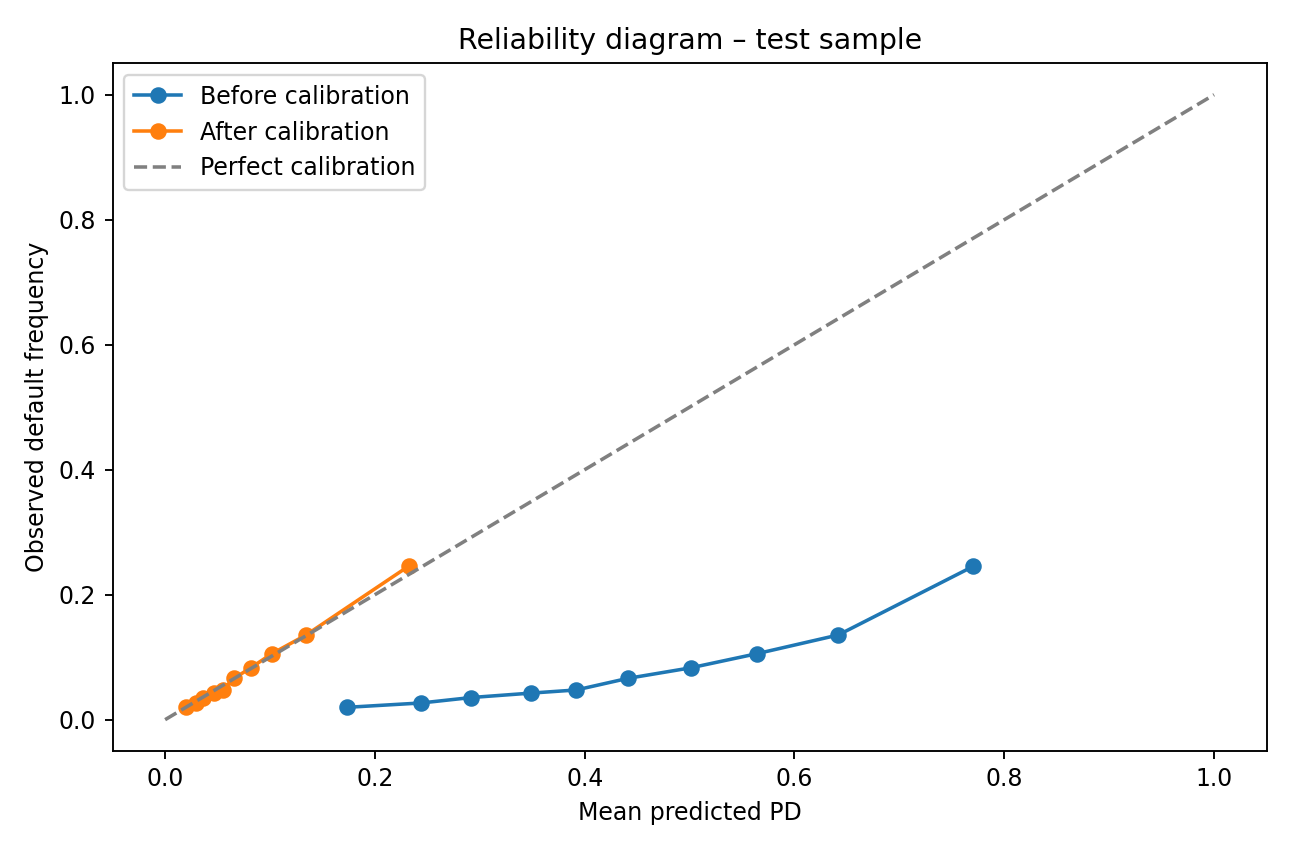

04_precision_recall.png


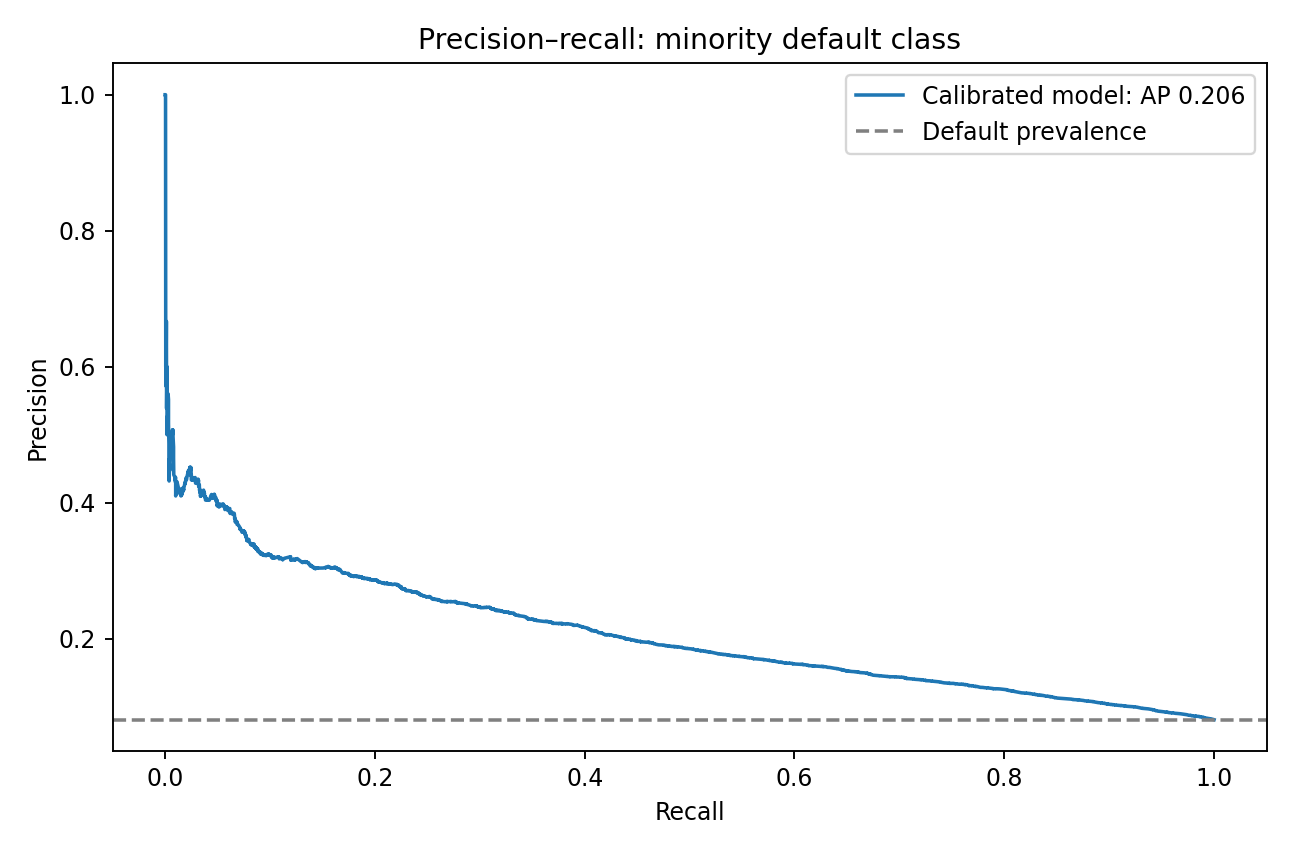

In [11]:
from IPython.display import display, Image
print("Detailed training-only IV rankings:")
display(pd.read_csv("results/information_value.csv"))
print("Test calibration deciles (aggregated):")
display(pd.read_csv("results/pd_deciles.csv"))
for chart in sorted(Path("results/figures").glob("*.png")):
    print(chart.name)
    display(Image(filename=str(chart)))

## 8 · Interpretation and limitations

- The training sample has many missing external-score observations. Missingness is retained as an explicit WoE category; no global pre-split imputation is performed.
- The three `EXT_SOURCE` predictors have the highest IV in the reference run; this does not establish a causal relationship.
- On the reference **61,503-account test set**, AUC was **0.7256**, average precision **0.2063**, calibrated mean PD **8.01%** versus observed event frequency **8.07%** and Brier score improved from **0.2103** to **0.0696**. These results come from a separate full 2026-11-23 local run on the supplied 25-column extract, not from cached notebook outputs.
- The illustrative test-sample EL was **1.200 billion** data currency units, or **3.26%** of the loan-amount exposure proxy, assuming **LGD=45%**. Neither EAD at default nor LGD is observed.
- A random stratified split tests within-sample generalization, **not** out-of-time stability, transportability, or real-world regulatory compliance. Further work could include time-based validation, challenger models, and uncertainty analysis for LGD/EAD.
